## Fragmentación y conectividad boscosa de los paisajes cafetaleros en la Zona de los Santos

### Introducción 

Esta investigación se realiza bajo el marco de investigacion cuantitativa para determinar los cambios en uso y cobertura de la tierra en la Zona de los Santos. Estudios previos documentan, entre 1984 y 2014, una expansión sostenida de la caficultura y un aumento de la cobertura forestal total, pero también advierten un mayor aislamiento de los remanentes boscosos como consecuencia del avance del monocultivo cafetalero, especialmente en zonas bajas de mayor aptitud agrícola (Arias Salazar & Corrales León, 2017; Consejo Territorial de Desarrollo Rural Los Santos, 2016).

En el presente estudio se exploro como la pérdida de cobertura arbórea reduce y separa los parches de bosque, por lo que es un indicador indirecto de la fragmentación del paisaje. Este cuaderno analiza esa pérdida en tres cantones de la Zona de los Santos, en la provincia de San José: Dota, León Cortés Castro y Tarrazú. Para ello se usan tablas de datos con pandas y gráficos con matplotlib.

**Preguntas que se responden:**

1. ¿Cómo se midió la superficie protegida de la Zona de los Santos y por qué fue necesario unir las áreas protegidas?
2. ¿Se puede relacionar la protección con la pérdida de cobertura arbórea de cada cantón?
3. ¿Qué tan concentrada está la pérdida en unos pocos años?

**Variables principales:**

| Variable | Descripción | Unidad |
|---|---|---|
| `canton` | Cantón analizado (Dota, León Cortés, Tarrazú) | Texto |
| `anio` | Año en que ocurrió la pérdida, de 2001 a 2025 | Año |
| `perdida_ha` | Superficie de cobertura arbórea perdida en ese año | Hectáreas (ha) |
| `cobertura_2000_ha` | Cobertura arbórea del cantón en el año 2000, usada como punto de partida | Hectáreas (ha) |

La pérdida es bruta: no descuenta la cobertura que pudo recuperarse en el mismo periodo.


### Carga de las bibliotecas y Datos del área de estudio 

In [2]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, TwoSlopeNorm


base = "https://raw.githubusercontent.com/Gittorres2000/Fragmentaci-n-y-Conectividad_3/main/"
cantones = gpd.read_file(base + "limite_cantonal.gpkg")
areas_protegidas = gpd.read_file(base + "areas_protegidas.gpkg")
rios = gpd.read_file(base + "rios.gpkg")

print(rios.crs)
print(rios.shape)
print(rios.geom_type.unique())   # tipo de geometría
rios.head()

EPSG:8908
(61, 13)
<ArrowStringArray>
['MultiLineString']
Length: 1, dtype: str


,id,id_mgn,cod_snit,descr_cat,nomb_río,cod_ugep,cod_ugec,cod_uged,nomb_ugep,nomb_ugec,nomd_uged,fecha_act,geometry
0,1.0,619.0,1501010301,Río,Río San Pablo,1.0,105.0,10501,San José,Tarrazú,San Marcos,2019-03-12,"MULTILINESTRING ((494840.2 1067879.86, 494844...."
1,6.0,624.0,1501010301,Río,Río Pirris (Parrita),1.0,105.0,10501,San José,Tarrazú,San Marcos,2025-05-07,"MULTILINESTRING ((497677.83 1067797.11, 497672..."
2,12.0,630.0,1501010301,Río,Río Parrita Chiquito,1.0,105.0,10501,San José,Tarrazú,San Marcos,2019-03-12,"MULTILINESTRING ((502578 1072619.79, 502559.78..."
3,20.0,665.0,1501010301,Río,Río Naranjillo,1.0,105.0,10502,San José,Tarrazú,San Lorenzo,2025-05-07,"MULTILINESTRING ((496210.49 1057138.28, 496191..."
4,31.0,676.0,1501010301,Río,Río Brujo,1.0,105.0,10502,San José,Tarrazú,San Lorenzo,2020-02-24,"MULTILINESTRING ((502487.78 1053929.51, 502486..."


### Carga y visualización de los datos csv para unirlos al área de estudio como vectores 

In [3]:
# Dirección del repositorio con los datos de Global Nature Watch
DATOS = "https://raw.githubusercontent.com/Gittorres2000/Fragmentaci-n-y-Conectividad_3/main/"

# Carga de la pérdida de cobertura arbórea de cada cantón
loss_dota = pd.read_csv(DATOS + "/treecover_loss_dota__ha.csv")
loss_leon = pd.read_csv(DATOS + "/treecover_loss_leon_cortez_ha.csv")
loss_tarrazu = pd.read_csv(DATOS + "/treecover_loss_tarrazu_ha.csv")

# Carga de la extensión de cobertura arbórea (año 2000) de cada cantón
ext_dota = pd.read_csv(DATOS + "/treecover_extent_dota_ha.csv")
ext_leon = pd.read_csv(DATOS + "/treecover_extent_leon_cortez_ha.csv")
ext_tarrazu = pd.read_csv(DATOS + "/treecover_extent_tarrazu_ha.csv")

**Variables principales:**

| Variable | Descripción | Unidad |
|---|---|---|
| `umd_tree_cover_loss__year` | Año en que ocurrió la pérdida de cobertura arbórea | Año |
| `umd_tree_cover_loss__ha` | Superficie de cobertura arbórea perdida en ese año | Hectáreas (ha) |
| `gfw_gross_emissions_co2e_all_gases__Mg` | Emisiones brutas asociadas a la pérdida, de todos los gases, expresadas en CO₂ equivalente | Megagramos de CO₂e (Mg CO₂e) |

### Unir perdida de cobertura (loss) y extension por (extent)

In [4]:
# Agregar el cantón a cada tabla antes de unirlas
loss_dota["canton"] = "Dota"
loss_leon["canton"] = "León Cortés"
loss_tarrazu["canton"] = "Tarrazú"
ext_dota["canton"] = "Dota"
ext_leon["canton"] = "León Cortés"
ext_tarrazu["canton"] = "Tarrazú"

# Unir  los tres cantones de cada tipo en una sola tabla
loss = pd.concat([loss_dota, loss_leon, loss_tarrazu], ignore_index=True)
extent = pd.concat([ext_dota, ext_leon, ext_tarrazu], ignore_index=True)

### renombrar columnas y revisar

In [5]:
# La columna de extensión puede tener un nombre largo; la buscamos por la palabra "extent"
col_ext = [c for c in extent.columns if "extent" in c][0]
print("Columna de extensión:", col_ext)

loss = loss.rename(columns={
    "umd_tree_cover_loss__year": "anio",
    "umd_tree_cover_loss__ha": "perdida_ha",
})
extent = extent.rename(columns={col_ext: "cobertura_2000_ha"})

loss = loss[["canton", "anio", "perdida_ha"]]
extent = extent[["canton", "cobertura_2000_ha"]]

print(loss.groupby("canton")["anio"].count())   # 25 por cantón
extent

Columna de extensión: umd_tree_cover_extent_2000__ha
canton
Dota           25
León Cortés    25
Tarrazú        25
Name: anio, dtype: int64


,canton,cobertura_2000_ha
0,Dota,37722.917823
1,León Cortés,10012.032061
2,Tarrazú,26058.041469


### Tabla resumen por cantón (pérdida total y porcentaje perdido)

In [6]:
# Pérdida total 2001-2025 por cantón
perdida_total = loss.groupby("canton")["perdida_ha"].sum().reset_index()

# Unir con la cobertura del año 2000
resumen = perdida_total.merge(extent, on="canton")

# Porcentaje de la cobertura del año 2000 que se perdió
resumen["porcentaje_perdido"] = (
    resumen["perdida_ha"] / resumen["cobertura_2000_ha"] * 100
).round(1)

resumen = resumen.sort_values("perdida_ha", ascending=False)
resumen

,canton,perdida_ha,cobertura_2000_ha,porcentaje_perdido
2,Tarrazú,1519.934251,26058.041469,5.8
0,Dota,952.170686,37722.917823,2.5
1,León Cortés,699.753292,10012.032061,7.0


### Unir el resumen a los polígonos (capa vectorial con datos)

In [7]:
# La capa dice "León Cortés Castro"; el resumen dice "León Cortés"
cantones["canton"] = cantones["CANTÓN"].replace({"León Cortés Castro": "León Cortés"})

capa = cantones[["canton", "geometry"]].merge(resumen, on="canton")

# Área desde la geometría: EPSG:8908 está en metros, así que m² / 10 000 = ha
capa["area_ha"] = capa.geometry.area / 10_000

print(len(capa), capa.crs)     # 3 filas, EPSG:8908
capa.drop(columns="geometry").round(1)

3 EPSG:8908


,canton,perdida_ha,cobertura_2000_ha,porcentaje_perdido,area_ha
0,Tarrazú,1519.9,26058.0,5.8,29126.8
1,Dota,952.2,37722.9,2.5,40444.4
2,León Cortés,699.8,10012.0,7.0,12189.5


### Operaciones espaciales 

dissolve de los tres cantones en la Zona de los Santos

In [8]:
zona = capa.dissolve(aggfunc={
    "perdida_ha": "sum",
    "cobertura_2000_ha": "sum",
    "area_ha": "sum",
})
zona["porcentaje_perdido"] = (zona["perdida_ha"] / zona["cobertura_2000_ha"] * 100).round(1)
zona["nombre"] = "Zona de los Santos"

# Verificaciones
print(len(zona), zona.geom_type.tolist(), zona.is_valid.tolist())   # 1, ['Polygon'], [True]
zona.drop(columns="geometry").round(1)

1 ['Polygon'] [True]


,perdida_ha,cobertura_2000_ha,area_ha,porcentaje_perdido,nombre
0,3171.9,73793.0,81760.6,4.3,Zona de los Santos


### Recortar las áreas protegidas a la zona (clip)

In [9]:
# Corregir geometrías inválidas, si las hubiera, antes de operar
areas_protegidas["geometry"] = areas_protegidas.make_valid()

# Quedarse solo con la parte de cada área protegida que cae dentro de la zona
asp_zona = gpd.clip(areas_protegidas, zona)
asp_zona["area_ha"] = asp_zona.geometry.area / 10_000   # EPSG:8908 está en metros

print(len(asp_zona))   # 7: las siete áreas intersectan la zona
asp_zona[["nombre_asp", "cat_manejo", "area_ha"]].sort_values("area_ha", ascending=False).round(1)

7


,nombre_asp,cat_manejo,area_ha
2,Los Santos,Reserva Forestal,31546.1
0,Los Quetzales,Parque Nacional,3925.1
3,Cerro Nara,Zona Protectora,2317.4
6,Monumento Natural Zona de los Santos,Monumento Natural,1861.0
1,Cerro Las Vueltas,Reserva Biologica,786.4
4,Quebrada Rosario,Zona Protectora,42.9
5,Caraigres,Zona Protectora,34.9


### dissolve por categoría de manejo y total protegido

In [10]:
# Agrupar las áreas por categoría de manejo
asp_cat = asp_zona.dissolve(
    by="cat_manejo",
    aggfunc={"nombre_asp": lambda s: ", ".join(s)},
).reset_index()

asp_cat["area_ha"] = asp_cat.geometry.area / 10_000
asp_cat["pct_zona"] = (asp_cat["area_ha"] / zona["area_ha"].iloc[0] * 100).round(1)

# Total protegido: una sola geometría, sin contar traslapes dos veces
asp_total = asp_zona.dissolve()
area_protegida = asp_total.geometry.area.sum() / 10_000

print("Suma sin dissolve:", round(asp_zona["area_ha"].sum()))
print("Con dissolve:     ", round(area_protegida))
print("% de la zona protegido:", round(area_protegida / zona["area_ha"].iloc[0] * 100, 1))

asp_cat[["cat_manejo", "nombre_asp", "area_ha", "pct_zona"]].sort_values("area_ha", ascending=False).round(1)

Suma sin dissolve: 40514
Con dissolve:      40514
% de la zona protegido: 49.6


,cat_manejo,nombre_asp,area_ha,pct_zona
3,Reserva Forestal,Los Santos,31546.1,38.6
1,Parque Nacional,Los Quetzales,3925.1,4.8
4,Zona Protectora,"Cerro Nara, Quebrada Rosario, Caraigres",2395.2,2.9
0,Monumento Natural,Monumento Natural Zona de los Santos,1861.0,2.3
2,Reserva Biologica,Cerro Las Vueltas,786.4,1.0


### Porcentaje protegido por cantón (overlay) y relación con la pérdida
Se cruza la protección con tus datos de pérdida

In [11]:
# Intersección: la parte de cada cantón que cae dentro de un área protegida
asp_en_cantones = gpd.overlay(
    capa[["canton", "geometry"]], asp_total[["geometry"]], how="intersection"
)
asp_en_cantones["area_protegida_ha"] = asp_en_cantones.geometry.area / 10_000

protegida = asp_en_cantones.groupby("canton")["area_protegida_ha"].sum().reset_index()

# Agregar a la capa principal; un cantón sin área protegida quedaría en 0
capa = capa.merge(protegida, on="canton", how="left")
capa["area_protegida_ha"] = capa["area_protegida_ha"].fillna(0)
capa["porcentaje_protegido"] = (capa["area_protegida_ha"] / capa["area_ha"] * 100).round(1)

capa[["canton", "area_ha", "area_protegida_ha", "porcentaje_protegido", "porcentaje_perdido"]].round(1)

,canton,area_ha,area_protegida_ha,porcentaje_protegido,porcentaje_perdido
0,Tarrazú,29126.8,3805.0,13.1,5.8
1,Dota,40444.4,35735.2,88.4,2.5
2,León Cortés,12189.5,973.5,8.0,7.0


### Tabla integrada por cantón y para toda la zona

In [12]:
# Una fila por cantón, con los datos de pérdida y de protección
tabla = capa[[
    "canton", "area_ha", "cobertura_2000_ha", "perdida_ha",
    "porcentaje_perdido", "area_protegida_ha", "porcentaje_protegido",
]].copy()

# Fila de totales: la Zona de los Santos (resultado del dissolve)
total = pd.DataFrame([{
    "canton": "Zona de los Santos",
    "area_ha": zona["area_ha"].iloc[0],
    "cobertura_2000_ha": zona["cobertura_2000_ha"].iloc[0],
    "perdida_ha": zona["perdida_ha"].iloc[0],
    "porcentaje_perdido": round(zona["perdida_ha"].iloc[0] / zona["cobertura_2000_ha"].iloc[0] * 100, 1),
    "area_protegida_ha": area_protegida,
    "porcentaje_protegido": round(area_protegida / zona["area_ha"].iloc[0] * 100, 1),
}])

# Cantones ordenados de mayor a menor pérdida relativa, y el total al final
tabla = pd.concat(
    [tabla.sort_values("porcentaje_perdido", ascending=False), total],
    ignore_index=True,
)

tabla = tabla.rename(columns={
    "canton": "Cantón",
    "area_ha": "Área (ha)",
    "cobertura_2000_ha": "Cobertura 2000 (ha)",
    "perdida_ha": "Pérdida 2001-2025 (ha)",
    "porcentaje_perdido": "Pérdida (% de la cobertura 2000)",
    "area_protegida_ha": "Área protegida (ha)",
    "porcentaje_protegido": "Protegido (% del área)",
})

formatos = {
    "Área (ha)": "{:,.0f}",
    "Cobertura 2000 (ha)": "{:,.0f}",
    "Pérdida 2001-2025 (ha)": "{:,.0f}",
    "Pérdida (% de la cobertura 2000)": "{:.1f} %",
    "Área protegida (ha)": "{:,.0f}",
    "Protegido (% del área)": "{:.1f} %",
}

# Mostrar con formato y la fila de totales en negrita
(tabla.style
    .format(formatos)
    .hide(axis="index")
    .apply(lambda f: ["font-weight: bold"] * len(f) if f.name == len(tabla) - 1 else [""] * len(f), axis=1))

Cantón,Área (ha),Cobertura 2000 (ha),Pérdida 2001-2025 (ha),Pérdida (% de la cobertura 2000),Área protegida (ha),Protegido (% del área)
León Cortés,"12,189","10,012",700,7.0 %,974,8.0 %
Tarrazú,"29,127","26,058","1,520",5.8 %,"3,805",13.1 %
Dota,"40,444","37,723",952,2.5 %,"35,735",88.4 %
Zona de los Santos,"81,761","73,793","3,172",4.3 %,"40,514",49.6 %


### Gráfico de líneas de la pérdida anual relativa por cantón

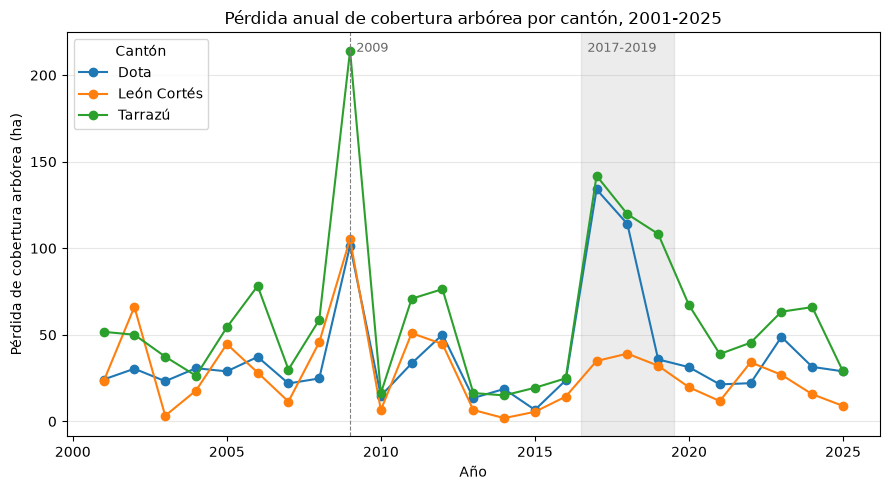

In [14]:
from matplotlib.ticker import StrMethodFormatter

# Tabla ancha: una fila por año, una columna por cantón
anual = loss.pivot_table(index="anio", columns="canton", values="perdida_ha", aggfunc="sum")

# Pérdida anual de cobertura arbórea por cantón, 2001-2025
fig, ax = plt.subplots(figsize=(9, 5))

anual.plot(kind="line", ax=ax, marker="o")

# Marcar los periodos de mayor pérdida
ax.axvline(2009, color="grey", linestyle="--", linewidth=0.8)
ax.axvspan(2016.5, 2019.5, color="grey", alpha=0.15)
ymax = ax.get_ylim()[1]
ax.text(2009.2, ymax * 0.95, "2009", fontsize=9, color="dimgrey")
ax.text(2016.7, ymax * 0.95, "2017-2019", fontsize=9, color="dimgrey")

ax.set_title("Pérdida anual de cobertura arbórea por cantón, 2001-2025")
ax.set_xlabel("Año")
ax.set_ylabel("Pérdida de cobertura arbórea (ha)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.legend(title="Cantón", loc="upper left")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretación del grafíco:** El gráfico muestra la pérdida anual de cobertura arbórea, en hectáreas, de cada cantón entre 2001 y 2025. Tarrazú es el cantón con mayor pérdida en 21 de los 25 años (promedio de 60.8 ha por año, frente a 38.1 ha en Dota y 28.0 ha en León Cortés). Se distinguen dos periodos excepcionales: 2009, con 421 ha perdidas en conjunto (214 ha en Tarrazú), y 2017-2019, con un segundo pico en el que Tarrazú pierde 142 ha y Dota 134 ha en 2017. Solo tres años (2009, 2017 y 2018) reúnen casi un tercio (31.7 %) de las 3 172 ha perdidas en la zona.

### Creación del mapa estatico en Geopandas

3 cantones con datos de 84


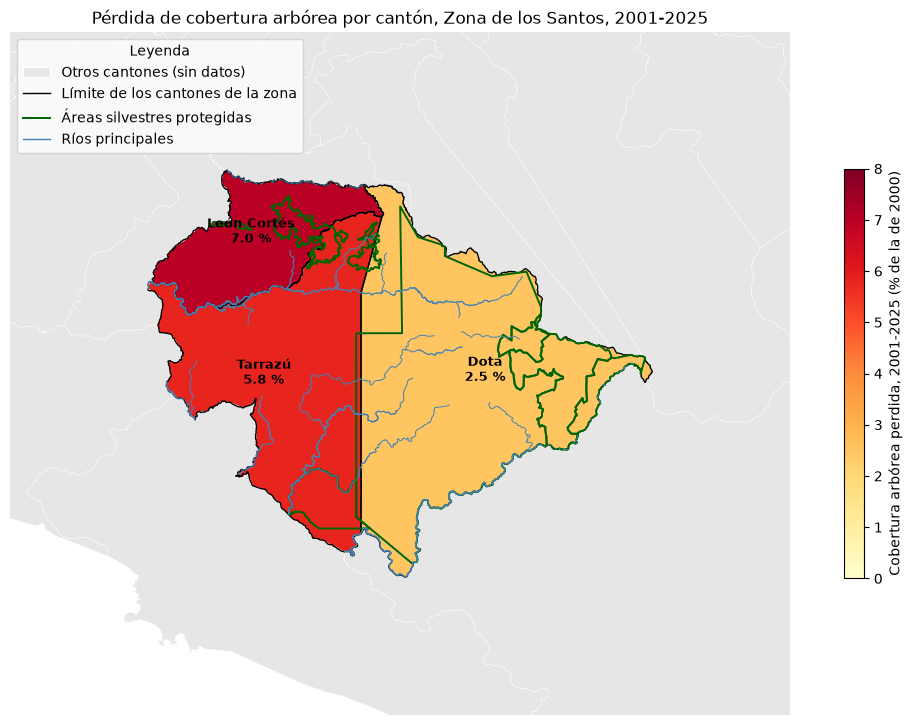

In [23]:

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.patheffects as pe


# Cantones del país (IGN, repositorio del curso), mismo SRC que tus capas: EPSG:8908
URL_CANTONES_CR = "https://raw.githubusercontent.com/gf0657-programacionsig/2026-ii/main/datos/ign/cantones.gpkg"
cantones_cr = gpd.read_file(URL_CANTONES_CR)
cantones_cr["canton"] = cantones_cr["canton"].replace({"León Cortés Castro": "León Cortés"})

# Unión por atributos: los 3 cantones de la zona reciben el dato; los demás quedan sin datos (NaN)
pais = cantones_cr.merge(capa[["canton", "porcentaje_perdido"]], on="canton", how="left")
print(pais["porcentaje_perdido"].notna().sum(), "cantones con datos de", len(pais))   # 3 de 84

# Ríos recortados a la zona de estudio
rios_zona = gpd.clip(rios, zona)

# Pérdida de cobertura arbórea por cantón, con el resto del país sin datos
fig, ax = plt.subplots(figsize=(11, 7.5))

pais.plot(
    ax=ax, column="porcentaje_perdido", cmap="YlOrRd", vmin=0, vmax=8,
    edgecolor="white", linewidth=0.3,
    legend=True,
    legend_kwds={"label": "Cobertura arbórea perdida, 2001-2025 (% de la de 2000)", "shrink": 0.6},
    missing_kwds={"color": "#E6E6E6"},
)

# Capas de apoyo: límite de los cantones de la zona, áreas protegidas y ríos
capa.boundary.plot(ax=ax, color="black", linewidth=1)
asp_zona.boundary.plot(ax=ax, color="darkgreen", linewidth=1.4)
rios_zona.plot(ax=ax, color="steelblue", linewidth=0.7)

# Nombre y valor de cada cantón (texto negro)
for fila in capa.itertuples():
    punto = fila.geometry.representative_point()
    ax.annotate(f"{fila.canton}\n{fila.porcentaje_perdido:.1f} %", (punto.x, punto.y),
                ha="center", fontsize=9, weight="bold", color="black")

# Acercar el mapa a la zona de estudio (los cantones vecinos quedan en gris como contexto)
minx, miny, maxx, maxy = capa.total_bounds
margen = 12000
ax.set_xlim(minx - margen, maxx + margen)
ax.set_ylim(miny - margen, maxy + margen)

# Leyenda de las capas
ax.legend(handles=[
    Patch(facecolor="#E6E6E6", edgecolor="white", label="Otros cantones (sin datos)"),
    Line2D([0], [0], color="black", linewidth=1, label="Límite de los cantones de la zona"),
    Line2D([0], [0], color="darkgreen", linewidth=1.4, label="Áreas silvestres protegidas"),
    Line2D([0], [0], color="steelblue", linewidth=1, label="Ríos principales"),
], loc="upper left", title="Leyenda")

ax.set_title("Pérdida de cobertura arbórea por cantón, Zona de los Santos, 2001-2025")
ax.set_axis_off()

plt.tight_layout()
plt.show()


## Mapa interactivo Folium

In [24]:
import folium
import branca.colormap as cm

# 1. Todas las capas a WGS84 (EPSG:4326), solo con los atributos que se muestran
cantones_web = capa[["canton", "cobertura_2000_ha", "perdida_ha", "porcentaje_perdido",
                     "area_ha", "area_protegida_ha", "porcentaje_protegido", "geometry"]].to_crs(4326)
cantones_web = cantones_web.round(1)

asp_web = asp_zona[["nombre_asp", "cat_manejo", "area_ha", "geometry"]].to_crs(4326)
asp_web["area_ha"] = asp_web["area_ha"].round(1)

# Ríos: el nombre del atributo depende de tu capa; revisa rios_zona.columns si no aparece
col_rio = next((c for c in rios_zona.columns
                if c.lower() in ("nombre", "name", "nom_rio", "nombre_rio", "rio", "río")), None)
rios_web = rios_zona[[col_rio, "geometry"]].to_crs(4326) if col_rio else rios_zona[["geometry"]].to_crs(4326)

for nombre, gdf in {"cantones": cantones_web, "áreas protegidas": asp_web, "ríos": rios_web}.items():
    assert gdf.crs.to_epsg() == 4326, f"{nombre} no está en WGS84"

# 2. Escala de color con leyenda (título y unidades), misma escala que el mapa estático (0-8 %)
escala = cm.LinearColormap(
    ["#FFFFB2", "#FED976", "#FD8D3C", "#E31A1C", "#800026"],
    vmin=0, vmax=8,
    caption="Cobertura arbórea perdida, 2001-2025 (% de la cobertura de 2000)"
)

def estilo_perdida(entidad):
    valor = entidad["properties"]["porcentaje_perdido"]
    color = "#E6E6E6" if valor is None else escala(valor)
    return {"fillColor": color, "color": "white", "weight": 1, "fillOpacity": 0.8}

# 3. Mapa base y capas
minx, miny, maxx, maxy = cantones_web.total_bounds
mapa = folium.Map(location=[(miny + maxy) / 2, (minx + maxx) / 2], zoom_start=10,
                  tiles="Esri.WorldGrayCanvas", control_scale=True)
folium.TileLayer("OpenStreetMap", name="OpenStreetMap").add_to(mapa)   # segundo mapa base

# Capa 1: cantones coloreados por pérdida relativa
folium.GeoJson(
    cantones_web, name="Pérdida de cobertura arbórea por cantón",
    style_function=estilo_perdida,
    highlight_function=lambda entidad: {"weight": 3, "color": "black", "fillOpacity": 0.95},
    tooltip=folium.GeoJsonTooltip(
        fields=["canton", "porcentaje_perdido", "perdida_ha", "cobertura_2000_ha", "porcentaje_protegido"],
        aliases=["Cantón", "Pérdida (% de la cobertura 2000)", "Pérdida 2001-2025 (ha)",
                 "Cobertura 2000 (ha)", "Área protegida (% del cantón)"],
        localize=True)
).add_to(mapa)

# Capa 2: áreas silvestres protegidas dentro de la zona
folium.GeoJson(
    asp_web, name="Áreas silvestres protegidas",
    style_function=lambda entidad: {"color": "darkgreen", "weight": 2,
                                    "fillColor": "darkgreen", "fillOpacity": 0.25},
    highlight_function=lambda entidad: {"weight": 4, "fillOpacity": 0.5},
    tooltip=folium.GeoJsonTooltip(
        fields=["nombre_asp", "cat_manejo", "area_ha"],
        aliases=["Área protegida", "Categoría de manejo", "Área dentro de la zona (ha)"],
        localize=True)
).add_to(mapa)

# Capa 3: ríos principales
folium.GeoJson(
    rios_web, name="Ríos principales",
    style_function=lambda entidad: {"color": "steelblue", "weight": 1.5},
    highlight_function=lambda entidad: {"weight": 4},
    tooltip=(folium.GeoJsonTooltip(fields=[col_rio], aliases=["Río"]) if col_rio else None)
).add_to(mapa)

escala.add_to(mapa)                       # leyenda de la variable coloreada
folium.LayerControl(collapsed=False).add_to(mapa)
mapa.fit_bounds([[miny, minx], [maxy, maxx]])

mapa

### Conclusiones: las respuestas a las preguntas de la introducción y sus limitaciones.

1. ¿Cómo se midió la superficie protegida de la Zona de los Santos y por qué fue necesario unir las áreas protegidas?

Las siete áreas silvestres protegidas intersectan la zona de estudio, y varias se traslapan entre sí. Por eso se unieron con dissolve en una sola geometría: así la superficie protegida de la zona no cuenta dos veces los traslapes. Luego, con overlay, se calculó qué parte de cada cantón cae dentro de esa geometría.

2. ¿Se puede relacionar la protección con la pérdida de cobertura arbórea de cada cantón?

Solo de forma descriptiva. León Cortés perdió la mayor proporción de su cobertura del año 2000 (7,0 %) y Dota la menor (2,5 %), pero los datos de pérdida están agregados por cantón. Por eso no se sabe si la pérdida ocurrió dentro o fuera de las áreas protegidas, y con solo tres cantones no es posible establecer una relación estadística.

3. ¿Qué tan concentrada está la pérdida en unos pocos años?

La pérdida se concentra en pocos años: 2009, 2017 y 2018 reúnen el 31,7 % de las 3 172 ha perdidas en la zona. Solo en 2009 se perdieron 421 ha en conjunto, 214 ha de ellas en Tarrazú. En el resto de los años la pérdida anual es más moderada.


### Limitaciones

- La pérdida es bruta: no descuenta la cobertura que pudo recuperarse en el mismo periodo, y los porcentajes parten de la cobertura del año 2000.
- La pérdida de cobertura arbórea es un indicador indirecto de la fragmentación: no mide el tamaño, el aislamiento ni la conectividad de los parches de bosque.
- La protección se calcula como proporción del área del cantón, sin distinguir si el área protegida coincide con las zonas donde ocurrió la pérdida, porque los datos de pérdida están agregados por cantón y no tienen ubicación dentro de él.
- Con solo tres cantones no es posible establecer una relación estadística entre protección y pérdida; los resultados son descriptivos.

## Fuente de los datos 

Global Forest Watch. (2026). *Tree cover loss in Dota, León Cortés Castro y Tarrazú, San José, Costa Rica* [Conjunto de datos]. World Resources Institute. Recuperado el 7 de octubre de 2026, de https://www.globalforestwatch.org

Hansen, M. C., Potapov, P. V., Moore, R., Hancher, M., Turubanova, S. A., Tyukavina, A., Thau, D., Stehman, S. V., Goetz, S. J., Loveland, T. R., Kommareddy, A., Egorov, A., Chini, L., Justice, C. O., & Townshend, J. R. G. (2013). High-resolution global maps of 21st-century forest cover change. *Science, 342*(6160), 850-853. https://doi.org/10.1126/science.1244693

Global Administrative Areas. (2018). *GADM database of Global Administrative Areas* (Versión 3.6) [Conjunto de datos]. https://gadm.org

## Declaración de uso de asistentes de inteligencia artificial

Para este trabajo utilicé el asistente Claude (Anthropic). Lo usé para consultar qué bibliotecas eran las adecuadas para cada paso y para entender cómo adaptar mis datos a operaciones espaciales como dissolve y overlay. También lo utilicé para depurar el código de la carga de datos, la tabla resumen y la tabla integrada por cantón, donde inicialmente tuve dificultades para unir las tablas de pérdida y extensión con los polígonos. En el gráfico de líneas, le pedí sugerencias para resaltar los periodos de mayor pérdida y para que la leyenda no tapara los picos.

En el mapa web interactivo, escribí la sintaxis de folium a partir de lo visto en el curso. Sin embargo, el código presentaba errores al integrar la tabla de datos con las capas del mapa.